# Practical 1 — Naïve Bayes Classifier

**Aim:** Build a Gaussian Naïve Bayes model to classify breast tumours as *benign* or *malignant*, evaluate it with a
train/test split and k-fold cross-validation, and report Accuracy, TP, TN, FP, FN, Error, Recall, Specificity, F1 and AUC.

**Dataset:** Breast Cancer Wisconsin (Diagnostic) — originally from the UCI Machine Learning Repository, bundled with
scikit-learn so the notebook runs offline. (You can swap in any CSV from <https://archive.ics.uci.edu/ml/datasets.php>
or <https://data.gov.in/> with `pd.read_csv`.)

**Idea:** Bayes' theorem says  P(class | x) ∝ P(class) · ∏ⱼ P(xⱼ | class).
"Naïve" = we assume the features are conditionally independent given the class.
For continuous features, *Gaussian* NB models P(xⱼ | class) with a normal distribution (mean μ and variance σ² per class, per feature).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

pd.set_option("display.precision", 4)
np.random.seed(42)

## Evaluation helpers (shared by all classification practicals)
The syllabus asks us to report **Accuracy, TP, TN, FP, FN, Error, Recall, Specificity, F1-score and AUC**.
* `classification_metrics` – builds the confusion matrix `[[TN, FP], [FN, TP]]` and derives every metric from it
  (formulas are in the docstring).
* `kfold_evaluate` – manual **stratified k-fold cross-validation**: for every fold it clones the model, trains on
  k-1 folds, tests on the held-out fold and records all metrics, so you can see each intermediate result.

In [2]:
from sklearn.base import clone
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import StratifiedKFold


def classification_metrics(y_true, y_pred, y_score=None):
    """Return all metrics required by the syllabus for a BINARY problem (positive class = 1).

    Accuracy    = (TP+TN)/(TP+TN+FP+FN)      Error       = 1 - Accuracy
    Recall      = TP/(TP+FN)  (sensitivity)  Specificity = TN/(TN+FP)
    Precision   = TP/(TP+FP)                 F1          = 2*P*R/(P+R)
    AUC         = area under the ROC curve (needs a continuous score, not the hard label)
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    return pd.Series({"TP": tp, "TN": tn, "FP": fp, "FN": fn, "Accuracy": accuracy,
                      "Error": 1 - accuracy, "Recall": recall, "Specificity": specificity,
                      "Precision": precision, "F1": f1, "AUC": auc})


def get_score(model, X):
    """Continuous score used for AUC: P(class=1) if available, otherwise the SVM-style decision value."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def kfold_evaluate(model, X, y, k=5, seed=42):
    """Stratified k-fold CV. Returns (per-fold table, mean/std summary)."""
    X, y = np.asarray(X), np.asarray(y)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    rows = []
    for fold, (tr, te) in enumerate(skf.split(X, y), start=1):
        m = clone(model).fit(X[tr], y[tr])                 # fresh, untrained copy each fold
        r = classification_metrics(y[te], m.predict(X[te]), get_score(m, X[te]))
        r.name = f"Fold {fold}"
        rows.append(r)
        print(f"Fold {fold}: train={len(tr)}, test={len(te)}, accuracy={r['Accuracy']:.4f}, AUC={r['AUC']:.4f}")
    folds = pd.DataFrame(rows)
    return folds, pd.DataFrame({"mean": folds.mean(), "std": folds.std()})


def plot_cm_roc(model, X_test, y_test, title=""):
    """Confusion matrix + ROC curve side by side."""
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax[0], cmap="Blues",
                                          display_labels=["Benign (0)", "Malignant (1)"])
    ax[0].set_title(f"Confusion matrix {title}")
    fpr, tpr, _ = roc_curve(y_test, get_score(model, X_test))
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, get_score(model, X_test)):.3f}")
    ax[1].plot([0, 1], [0, 1], "k--", label="Chance")
    ax[1].set(xlabel="False Positive Rate (1 - Specificity)", ylabel="True Positive Rate (Recall)",
              title=f"ROC curve {title}")
    ax[1].legend(); plt.tight_layout(); plt.show()

## Step 1 — Load and inspect the data

In [3]:
data = load_breast_cancer(as_frame=True)
X_df = data.data                                  # 30 numeric features
y_s = (data.target == 0).astype(int)              # flip so that 1 = MALIGNANT (the "positive" class), 0 = benign
df = X_df.assign(target=y_s)

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("\nClass balance (1 = malignant):")
print(y_s.value_counts().rename({0: "benign", 1: "malignant"}))
df.head()

Shape: (569, 31)
Missing values: 0

Class balance (1 = malignant):
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,1
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,1
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,1
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,1
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,1


## Step 2 — Train / test split
`train_test_split` shuffles the rows (seeded by `random_state`) and cuts them 80 % / 20 %.
`stratify=y` keeps the malignant/benign ratio identical in both parts, so the test set is representative.

In [4]:
X = X_df.values
y = y_s.values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Malignant share  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (455, 30)  Test: (114, 30)
Malignant share  train: 0.374 | test: 0.368


## Step 3 — What does `GaussianNB.fit()` actually do? (manual walk-through)
Training Naïve Bayes is just **counting and averaging** – there is no iterative optimisation:
1. **Class priors** P(c) = (#samples of class c) / (#samples).
2. For each class c and each feature j compute the **mean μ_cj** and **variance σ²_cj** of the training rows of that class.
3. A tiny value (`var_smoothing × largest variance`) is added to every variance so we never divide by zero.

Let us do exactly that with NumPy.

In [5]:
classes = np.unique(y_train)
priors = np.array([(y_train == c).mean() for c in classes])
means = np.array([X_train[y_train == c].mean(axis=0) for c in classes])
variances = np.array([X_train[y_train == c].var(axis=0) for c in classes])      # population variance (ddof=0)
epsilon = 1e-9 * X_train.var(axis=0).max()                                       # var_smoothing = 1e-9 (sklearn default)
variances = variances + epsilon

print("Step 3.1  priors  P(benign), P(malignant) =", priors.round(4))
print("Step 3.2  means shape =", means.shape, "(classes x features)")
print("          first 5 feature means  benign   :", means[0, :5].round(3))
print("          first 5 feature means  malignant:", means[1, :5].round(3))
print("Step 3.3  smoothing epsilon added to every variance =", epsilon)

Step 3.1  priors  P(benign), P(malignant) = [0.6264 0.3736]
Step 3.2  means shape = (2, 30) (classes x features)
          first 5 feature means  benign   : [1.21550e+01 1.80490e+01 7.81040e+01 4.63857e+02 9.20000e-02]
          first 5 feature means  malignant: [1.75370e+01 2.17130e+01 1.15873e+02 9.87699e+02 1.03000e-01]
Step 3.3  smoothing epsilon added to every variance = 0.00033838174019611145


## Step 4 — What does `predict()` do? (one test sample, by hand)
For a sample **x** and each class c we compute the *log joint probability*

`log P(c) + Σⱼ log N(xⱼ ; μ_cj, σ²_cj)`

(logs are used because multiplying 30 tiny probabilities would underflow). The class with the **largest** value wins.
Converting the log-joints with a softmax gives P(c | x).

In [6]:
x0 = X_test[0]
print("Test sample 0 – true label:", y_test[0], "\n")

log_joint = []
for i, c in enumerate(classes):
    log_prior = np.log(priors[i])
    log_likelihoods = norm.logpdf(x0, loc=means[i], scale=np.sqrt(variances[i]))   # one log N(.) per feature
    log_joint.append(log_prior + log_likelihoods.sum())
    print(f"class {c}: log prior = {log_prior:.4f} | sum of 30 log-likelihoods = {log_likelihoods.sum():.4f} "
          f"| log joint = {log_joint[-1]:.4f}")

log_joint = np.array(log_joint)
posterior = np.exp(log_joint - log_joint.max()); posterior /= posterior.sum()        # softmax = Bayes normalisation
print("\nPosterior P(class | x):", posterior.round(6))
print("Manual prediction:", classes[np.argmax(log_joint)])

Test sample 0 – true label: 0 

class 0: log prior = -0.4678 | sum of 30 log-likelihoods = 8.1585 | log joint = 7.6907
class 1: log prior = -0.9845 | sum of 30 log-likelihoods = -24.5404 | log joint = -25.5249

Posterior P(class | x): [1. 0.]
Manual prediction: 0


## Step 5 — Fit scikit-learn's `GaussianNB` and confirm it matches our manual numbers

In [7]:
nb = GaussianNB()
nb.fit(X_train, y_train)

print("Priors match         :", np.allclose(nb.class_prior_, priors))
print("Means match          :", np.allclose(nb.theta_, means))
print("Variances match      :", np.allclose(nb.var_, variances))
print("Posterior (sklearn)  :", nb.predict_proba(x0.reshape(1, -1))[0].round(6))
print("Posterior (manual)   :", posterior.round(6))

Priors match         : True
Means match          : True
Variances match      : True
Posterior (sklearn)  : [1. 0.]
Posterior (manual)   : [1. 0.]


## Step 6 — Evaluation on the hold-out test set
`predict()` gives the hard labels; `predict_proba()[:, 1]` gives P(malignant), needed for the ROC/AUC.

In [8]:
y_pred = nb.predict(X_test)
test_metrics = classification_metrics(y_test, y_pred, nb.predict_proba(X_test)[:, 1])
print(test_metrics.round(4).to_string())
print()
print(classification_report(y_test, y_pred, target_names=["benign", "malignant"]))

TP             35.0000
TN             72.0000
FP              0.0000
FN              7.0000
Accuracy        0.9386
Error           0.0614
Recall          0.8333
Specificity     1.0000
Precision       1.0000
F1              0.9091
AUC             0.9934



              precision    recall  f1-score   support

      benign       0.91      1.00      0.95        72
   malignant       1.00      0.83      0.91        42

    accuracy                           0.94       114
   macro avg       0.96      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



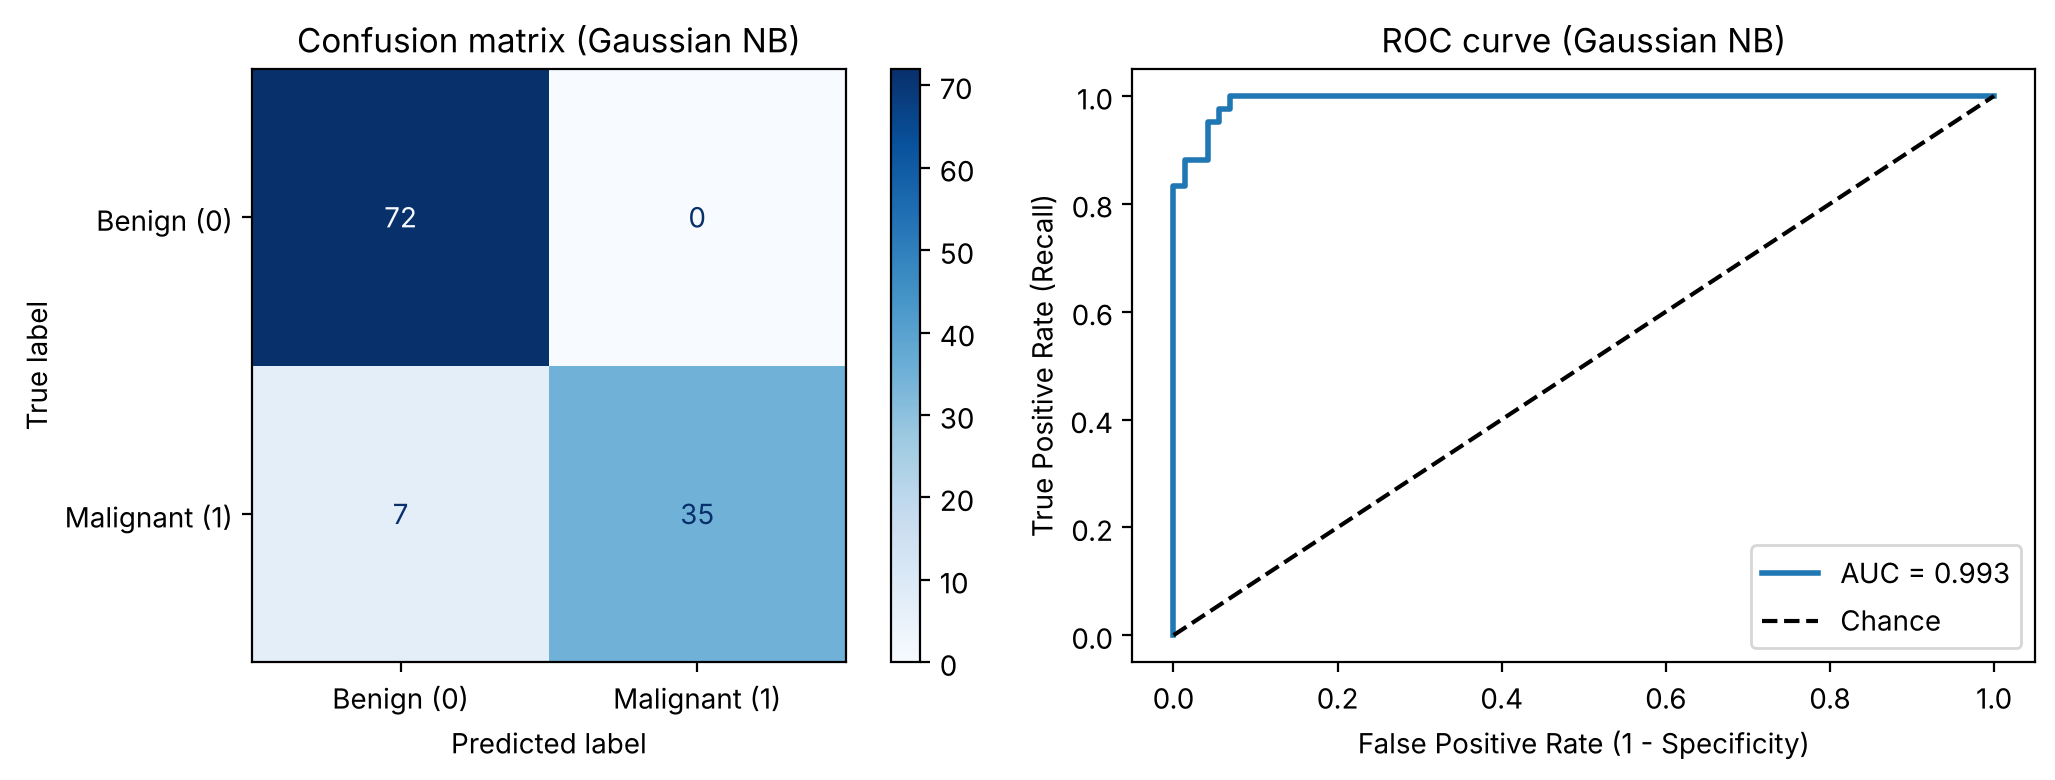

In [9]:
plot_cm_roc(nb, X_test, y_test, title="(Gaussian NB)")

**Reading the confusion matrix:** TP = malignant correctly flagged, TN = benign correctly cleared,
FP = benign wrongly flagged (false alarm), FN = malignant missed (the costly error in medicine – watch *Recall*).

## Step 7 — k-fold cross-validation (k = 5)
A single split can be lucky or unlucky. Stratified 5-fold CV splits the data into 5 parts; every part is the test
set exactly once. The mean ± std over folds is a more reliable estimate.

In [10]:
folds, summary = kfold_evaluate(GaussianNB(), X, y, k=5)
print()
display(folds.round(4))
display(summary.round(4))

Fold 1: train=455, test=114, accuracy=0.9649, AUC=0.9964
Fold 2: train=455, test=114, accuracy=0.9035, AUC=0.9725
Fold 3: train=455, test=114, accuracy=0.9298, AUC=0.9881
Fold 4: train=455, test=114, accuracy=0.9298, AUC=0.9820
Fold 5: train=456, test=113, accuracy=0.9646, AUC=0.9923



,TP,TN,FP,FN,Accuracy,Error,Recall,Specificity,Precision,F1,AUC
Fold 1,41.0,69.0,2.0,2.0,0.9649,0.0351,0.9535,0.9718,0.9535,0.9535,0.9964
Fold 2,35.0,68.0,3.0,8.0,0.9035,0.0965,0.8140,0.9577,0.9211,0.8642,0.9725
Fold 3,34.0,72.0,0.0,8.0,0.9298,0.0702,0.8095,1.0000,1.0000,0.8947,0.9881
Fold 4,40.0,66.0,6.0,2.0,0.9298,0.0702,0.9524,0.9167,0.8696,0.9091,0.9820
Fold 5,38.0,71.0,0.0,4.0,0.9646,0.0354,0.9048,1.0000,1.0000,0.9500,0.9923


,mean,std
TP,37.6000,3.0496
TN,69.2000,2.3875
FP,2.2000,2.4900
FN,4.8000,3.0332
Accuracy,0.9385,0.0262
Error,0.0615,0.0262
Recall,0.8868,0.0713
Specificity,0.9692,0.0346
Precision,0.9488,0.0555
F1,0.9143,0.0378


## Step 8 — Visualising what the model learned
For the two most separating features the class-conditional Gaussians P(xⱼ | class) are plotted. NB multiplies such
curves across all features. The more the two bells are apart, the more informative the feature.

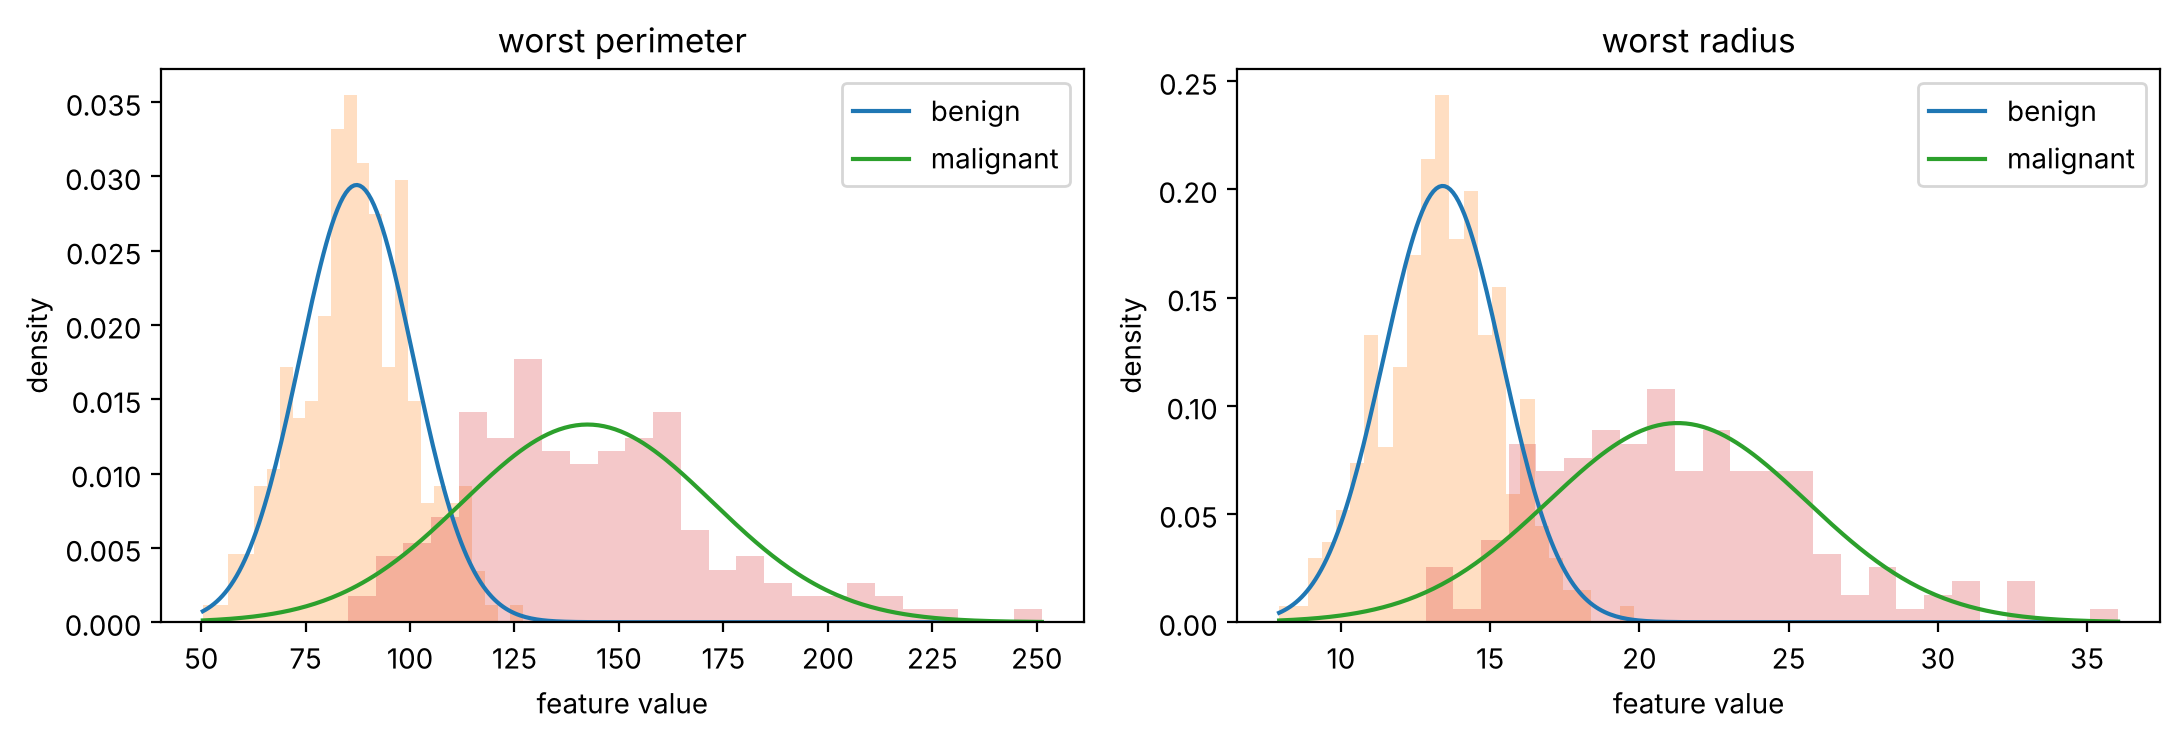

In [11]:
sep = np.abs(means[1] - means[0]) / np.sqrt(variances.mean(axis=0))
top = np.argsort(sep)[::-1][:2]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, j in zip(axes, top):
    grid = np.linspace(X[:, j].min(), X[:, j].max(), 300)
    for i, (c, name) in enumerate(zip(classes, ["benign", "malignant"])):
        ax.plot(grid, norm.pdf(grid, means[i, j], np.sqrt(variances[i, j])), label=name)
        ax.hist(X_train[y_train == c, j], bins=25, density=True, alpha=0.25)
    ax.set_title(X_df.columns[j]); ax.set_xlabel("feature value"); ax.set_ylabel("density"); ax.legend()
plt.tight_layout(); plt.show()

## Step 9 — Summary
Test-set versus cross-validated performance side by side.

In [12]:
summary_tbl = pd.DataFrame({"Hold-out test": test_metrics, "5-fold CV mean": summary["mean"]})
display(summary_tbl.round(4))

,Hold-out test,5-fold CV mean
TP,35.0000,37.6000
TN,72.0000,69.2000
FP,0.0000,2.2000
FN,7.0000,4.8000
Accuracy,0.9386,0.9385
Error,0.0614,0.0615
Recall,0.8333,0.8868
Specificity,1.0000,0.9692
Precision,1.0000,0.9488
F1,0.9091,0.9143


### Conclusion
* Gaussian Naïve Bayes needs only class priors and per-class means/variances, so it trains instantly.
* Even though the features are strongly correlated (violating the "naïve" independence assumption) it still gives high accuracy and AUC on this data.
* The CV mean agrees with the test-set numbers, and the small standard deviation shows the result is stable.
* Because its probabilities tend to be over-confident, use AUC / Recall rather than raw probabilities when interpreting results.